For a BH of mass $M$ spin $\chi\in [0,1]$, the irreducible mass is 
$$
M_{\rm irr} = M \sqrt{\frac{1+\sqrt{1-\chi^2}}{2}}
$$
For convenience, let us define 

$$f(\chi) = \sqrt{\frac{1+\sqrt{1-\chi^2}}{2}}$$

Suppose you have repeated measurments of $M$ and $\chi$. This is just because we're still frequentists for now. When we will put our Bayesian hat on, these distributions will be the *posterior samples* from a single measurement.

Let's assume that

- the spin $\chi$ is uniformly distributed between 0 and 1.
- the mass $M$ is normally distributed with mean $\mu$ and standard deviation $\sigma$.
- (masses and spins are uncorrelated)

These are simplistic assumption that, however, are not too far from what we are now measuring with gravitational-wave detectors. It's a toy model, but not a totally unreasonable one.

1. Start with a value of $\sigma=0.02$. Note that $\mu$ is a scale and not a parameter: you can normalize all quantities with a dimension of mass by $\mu$. Just set $\mu=1$ in your code and remember that all masses in the problem are measured in units of $\mu$. 

2. Plot the resulting pdf of $M_{\rm irr}$. First try an histogram with one the rules of thumb we've seen above.

*Hint (for point 2)*: You don't know the functional form of the pdf of $M_{\rm irr}$... but you don't need it if you just want to generate samples! That's the nice thing about numerics!

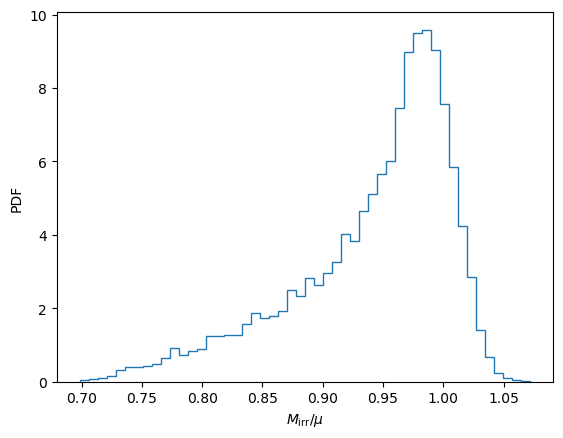

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp

np.random.seed(42)

M = np.random.normal(1,0.02,10000)
spin = np.random.uniform(0,1,10000)

M_irr = M*np.sqrt((1+np.sqrt(1-spin**2))/2)

plt.hist(M_irr, bins='fd', density=True, histtype='step')
plt.xlabel(r'$M_{\mathrm{irr}} / \mu$')
plt.ylabel('PDF')
plt.show()

3. Using the same samples, plot the distribution of $M_{\rm irr}$ using a KDE.

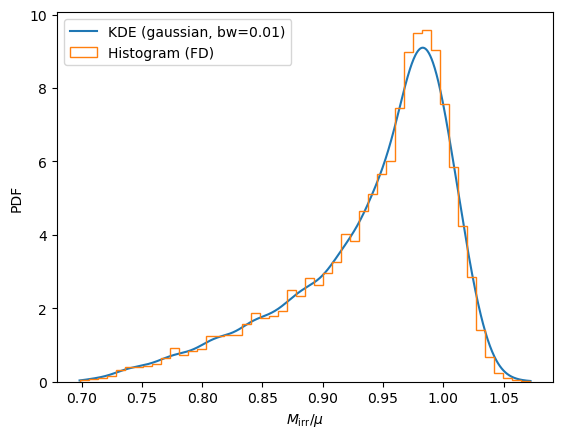

In [14]:
from sklearn.neighbors import KernelDensity

xgrid = np.linspace(M_irr.min(),M_irr.max(),1000)

def kde_sklearn(data, bandwidth = 1.0, kernel="gaussian"):
    kde_skl = KernelDensity(bandwidth = bandwidth, 
                            kernel=kernel)
    kde_skl.fit(data[:, np.newaxis])
    log_pdf = kde_skl.score_samples(xgrid[:, np.newaxis]) # sklearn returns log(density)
    return np.exp(log_pdf)

pdf_kde = kde_sklearn(M_irr, bandwidth=0.01, kernel="gaussian") 
plt.plot(xgrid, pdf_kde, label='KDE (gaussian, bw=0.01)')
plt.hist(M_irr, bins='fd', density=True, histtype='step', label='Histogram (FD)')
plt.xlabel(r'$M_{\mathrm{irr}} / \mu$')
plt.ylabel('PDF')
plt.legend()
plt.show()

4. Compute the KS distance between ${M_{\rm irr}}/\mu$ and ${f}$ as a function of $\sigma$. Discuss the limits at large and small values of $\sigma$. 
5. Compute the KS distance between ${M_{\rm irr}}$ and $M$ as a function of $\sigma$. Discuss the limits at large and small values of $\sigma$.

*Hint (for points 4 and 5)*. This is a KS test between two sets for samples, `scipy.stats.ks_2samp`.
You should find that (i) $M_{\rm irr}$ is distributed like $f$ if ${\sigma}\ll \mu$ and (ii) $M_{\rm irr}$ is distributed like $M$ if  $\sigma\gg \mu$.

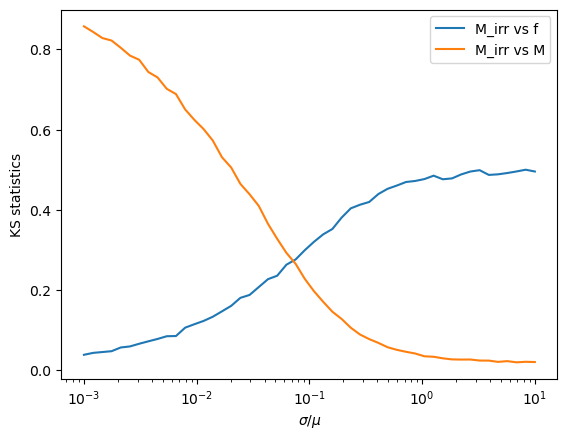

In [15]:
sigmas = np.logspace(-3, 1, 50)
ks_f = []
ks_M = []
mu = 1.0

for sigma in sigmas:
    M = np.random.normal(1, sigma, 10000)
    spin = np.random.uniform(0, 1, 10000)
    
    f_vals = np.sqrt((1 + np.sqrt(1 - spin**2)) / 2)
    M_irr = M * f_vals
    
    ks_f.append(ks_2samp(M_irr/mu , f_vals).statistic)
    ks_M.append(ks_2samp(M_irr, M).statistic)

plt.plot(sigmas, ks_f, label='M_irr vs f')
plt.plot(sigmas, ks_M, label='M_irr vs M')
plt.xscale('log')
plt.xlabel(r"$\sigma / \mu$")
plt.ylabel('KS statistics')
plt.legend()
plt.show()

7. [**Optional, not examinable**] Compute the pdf of $f$ from its mathematical definition (pen and paper!). Verify this result: 

$$
\pi(f) = 2\frac{2 f^2-1}{\sqrt{1 - f^2}}\,.
$$

8. [**Optional, not examinable**]  Compute the pdfs of $M_{\rm irr}$ from its mathematical definition (pen and paper!). Verify this result:

$$
p(M_{\mathrm{irr}})  = \frac{\sqrt{2/\pi}}{\sigma} \int_{1/\sqrt{2}}^1 \exp\left[-\frac{(M_{\mathrm{irr}}/f -\mu)^2}{2\sigma^2}\right]  \frac{2 f^2-1}{f \sqrt{1 - f^2}}  \,\, \mathrm{d}f\,.
$$


The this expression is only semi-analytic; that integral should then be solved numerically.

*Hint (for point 8)*: You want to use [this theorem](https://en.wikipedia.org/wiki/Distribution_of_the_product_of_two_random_variables) for the product of two random variables. 

9. Using the expressions from point 7 and 8, plot those pdfs check that they agree with your KDE reconstructions.


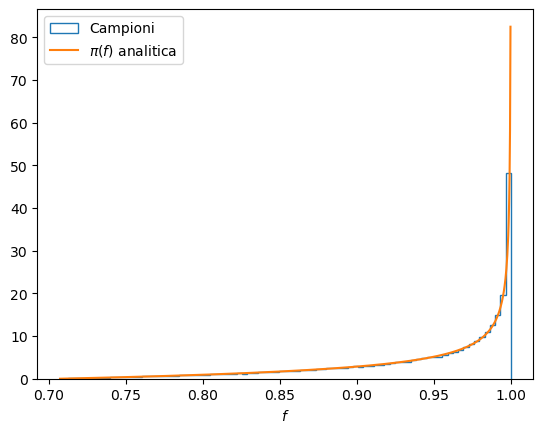

In [16]:
# Verifica numerica vs analitica per pdf di f
chi = np.random.uniform(0, 1, 100000)
f_vals = np.sqrt((1 + np.sqrt(1 - chi**2)) / 2)

f_grid = np.linspace(1/np.sqrt(2), 1, 1000)[:-1]
pdf_f_analytic = 2 * (2*f_grid**2 - 1) / np.sqrt(1 - f_grid**2)

plt.hist(f_vals, bins='fd', density=True, histtype='step', label='Campioni')
plt.plot(f_grid, pdf_f_analytic, label=r'$\pi(f)$ analitica')
plt.xlabel('$f$')
plt.legend()
plt.show()

In [17]:
sigma = 0.02
mu = 1.0
N = 10000
M = np.random.normal(mu, sigma, N)
chi = np.random.uniform(0, 1, N)
f_vals = np.sqrt((1 + np.sqrt(1 - chi**2)) / 2)
M_irr = M * f_vals
# Poi calcola la pdf e plotta
x = np.linspace(min(1 - 5*sigma, 1/np.sqrt(2)), 1 + 5*sigma, N)

def integrand(f, x_val):
    return ((2/np.pi)**0.5 / sigma) * np.exp(-(x_val/f - mu)**2 / (2*sigma**2)) * (2*f**2 - 1) / (f * np.sqrt(1 - f**2))

Mirr_pdf = [scipy.integrate.quad(lambda f: integrand(f, xt), 1/2**0.5, 1)[0] for xt in x]

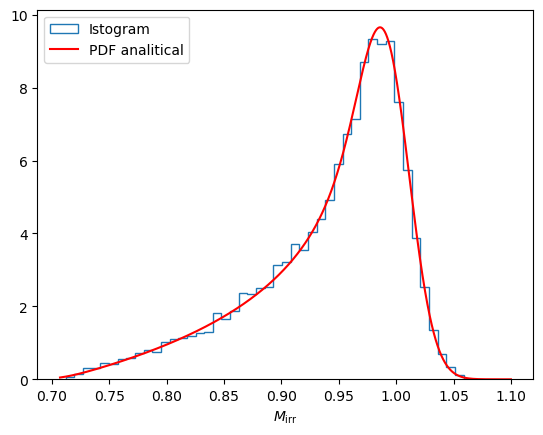

In [19]:
plt.hist(M_irr, bins='fd', density=True, histtype='step', label='Istogram')
plt.plot(x, Mirr_pdf, label='PDF analitical', color='red')
plt.xlabel(r'$M_{\mathrm{irr}}$')
plt.legend()
plt.show()


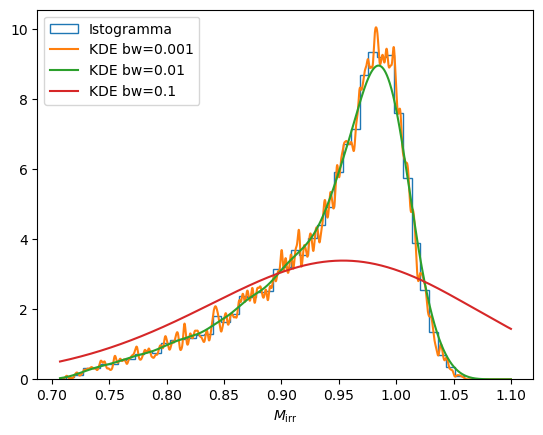

In [20]:
plt.hist(M_irr, bins='fd', density=True, histtype='step', label='Istogramma')

# Aggiungi KDE con diversi bandwidth
for bw in [0.001, 0.01, 0.1]:
    kde = KernelDensity(bandwidth=bw, kernel='gaussian')
    kde.fit(M_irr[:, np.newaxis])
    log_dens = kde.score_samples(x[:, np.newaxis])
    plt.plot(x, np.exp(log_dens), label=f'KDE bw={bw}')

plt.legend()
plt.xlabel(r'$M_{\mathrm{irr}}$')
plt.show()